# Nigeria's public finances: a debt problem or a revenue problem?

Nigeria's government debt has climbed from about 5% of GDP in 2008 to almost 40% in 2024, and the cost of servicing it dominates the public debate. This notebook asks whether **the size of the debt** or **the size of the revenue base** is the bigger problem.

**Questions**
1. How has Nigeria's debt ratio changed, and when did it jump?
2. How much of government revenue goes to interest payments?
3. How does Nigeria compare with seven other large African economies?
4. How big is Nigeria's revenue gap, in percentage points and in dollars?

**Data:** IMF World Economic Outlook (October 2026) and IMF Public Finances in Modern History (December 2025), both via the IMF DataMapper API. See the README for definitions and caveats.

In [1]:
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = ROOT / "data" / "processed" / "fiscal.db"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)

con = sqlite3.connect(DB)

# Load every named query from sql/analysis.sql so the SQL lives in one reviewable file.
sql_text = (ROOT / "sql" / "analysis.sql").read_text()
QUERIES = dict(re.findall(r"-- name: (\w+)\n(.*?)(?=\n-- name:|\Z)", sql_text, re.S))

def q(name: str) -> pd.DataFrame:
    return pd.read_sql(QUERIES[name], con)

pd.set_option("display.precision", 1)
list(QUERIES)

['nigeria_fiscal_panel',
 'debt_turning_points',
 'era_averages',
 'peer_comparison',
 'revenue_gap_vs_peers']

In [2]:
# Chart style: thin marks, recessive grid, text in neutral ink (never the series colour).
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b9b8b3"
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8984"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#d9d8d4", "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe8", "grid.linewidth": 0.8,
    "lines.linewidth": 2,
})

def source_note(fig, text="Source: IMF World Economic Outlook (Oct 2026), IMF Public Finances in Modern History (Dec 2025)"):
    fig.text(0.01, -0.02, text, fontsize=8.5, color=INK_3, ha="left")

## 1. The debt ratio: low by global standards, but rising fast

In [3]:
panel = q("nigeria_fiscal_panel")
panel.loc[panel.year >= 2006, ["year", "debt_pct_gdp", "revenue_pct_gdp", "interest_pct_gdp",
                               "interest_pct_revenue", "real_gdp_growth", "inflation", "is_projection"]]

,year,debt_pct_gdp,revenue_pct_gdp,interest_pct_gdp,interest_pct_revenue,real_gdp_growth,inflation,is_projection
16,2006,6.7,15.0,0.5,3.2,6.7,8.2,0
17,2007,5.8,12.1,0.4,3.7,7.3,5.4,0
18,2008,5.2,14.3,0.5,3.2,7.2,11.6,0
19,2009,6.1,7.2,0.5,6.4,8.4,12.5,0
20,2010,6.7,8.8,0.4,5.1,11.3,13.7,0
21,2011,12.4,12.6,0.6,4.7,4.9,10.8,0
22,2012,12.5,10.4,0.7,6.6,4.3,12.2,0
23,2013,13.0,8.2,0.7,8.6,5.4,8.5,0
24,2014,15.8,7.8,0.7,8.9,6.3,8.0,0
25,2015,14.9,5.1,0.8,15.6,2.7,9.0,0


In [4]:
q("debt_turning_points")

,year,debt_pct_gdp,change_pp
0,2023,36.3,6.5
1,2011,12.4,5.7
2,2020,25.7,4.3
3,2022,29.8,3.2
4,2024,39.3,3.0


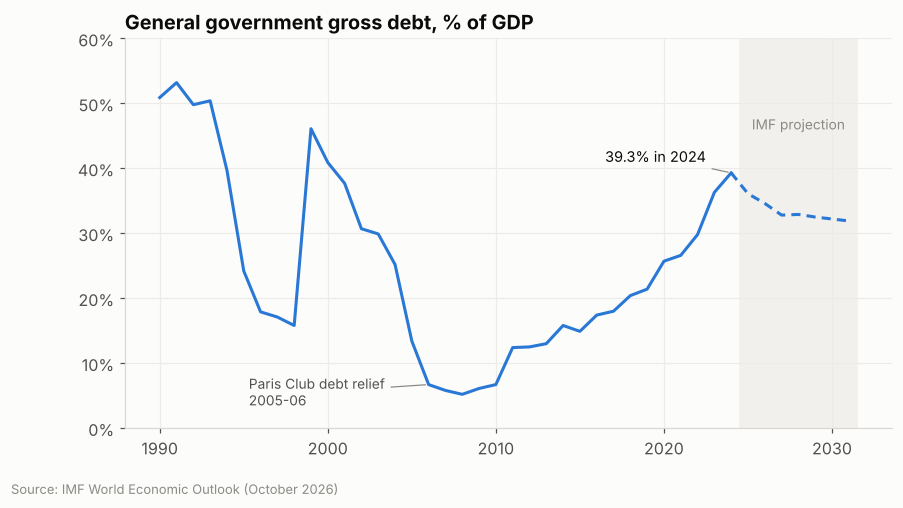

In [5]:
actual = panel[panel.is_projection == 0]
proj = panel[panel.year >= actual.year.max()]  # start projections at the last actual year so the line joins

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(actual.year, actual.debt_pct_gdp, color=BLUE)
ax.plot(proj.year, proj.debt_pct_gdp, color=BLUE, linestyle=(0, (3, 2)))
ax.axvspan(2024.5, 2031.5, color="#f1f0ed", zorder=0)
ax.text(2028, 46, "IMF projection", ha="center", color=INK_3, fontsize=9)

ax.annotate("Paris Club debt relief\n2005-06", xy=(2006, 6.7), xytext=(1995.3, 3.5),
            fontsize=9, color=INK_2, arrowprops=dict(arrowstyle="-", color=INK_3, lw=0.8))
last = actual.iloc[-1]
ax.annotate(f"{last.debt_pct_gdp:.1f}% in {int(last.year)}", xy=(last.year, last.debt_pct_gdp),
            xytext=(2016.5, 41), fontsize=9.5, color=INK, arrowprops=dict(arrowstyle="-", color=INK_3, lw=0.8))

ax.set_ylim(0, 60)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("General government gross debt, % of GDP")
source_note(fig, "Source: IMF World Economic Outlook (October 2026)")
fig.savefig(CHARTS / "01_debt_ratio.png")
plt.show()

**Reading:** After debt relief in 2005-06 the ratio fell to about 5% of GDP. It has risen every year since 2015, and the single biggest jump was in 2023 (+6.5 percentage points), the year of the naira's devaluation, which raises the naira value of foreign-currency debt. Even at 39% in 2024, the ratio is low compared with most emerging economies.

## 2. The real squeeze: interest payments versus revenue

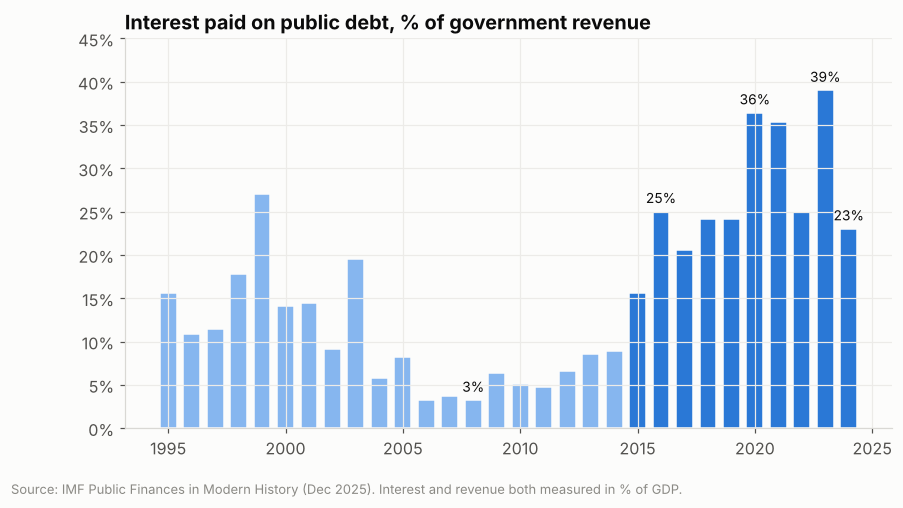

In [6]:
hist = panel[(panel.year >= 1995) & panel.interest_pct_revenue.notna()]

fig, ax = plt.subplots(figsize=(9, 4.6))
colors = [BLUE if y >= 2015 else "#86b6ef" for y in hist.year]
ax.bar(hist.year, hist.interest_pct_revenue, color=colors, width=0.72, edgecolor="#fcfcfb", linewidth=1)
for y in (2008, 2016, 2020, 2023, 2024):
    v = hist.loc[hist.year == y, "interest_pct_revenue"].item()
    ax.text(y, v + 1, f"{v:.0f}%", ha="center", fontsize=9, color=INK)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 45)
ax.set_title("Interest paid on public debt, % of government revenue")
source_note(fig, "Source: IMF Public Finances in Modern History (Dec 2025). Interest and revenue both measured in % of GDP.")
fig.savefig(CHARTS / "02_interest_to_revenue.png")
plt.show()

In [7]:
q("era_averages")

,era,avg_debt_pct_gdp,avg_revenue_pct_gdp,avg_interest_pct_gdp,avg_real_growth,avg_inflation
0,1) 2006-2014 post debt relief,9.4,10.7,0.6,6.9,10.1
1,2) 2015-2022 after oil crash,21.8,5.2,1.3,0.6,14.2
2,3) 2023-2024 reform years,37.8,9.0,2.7,3.7,29.0


**Reading:** In 2008 interest absorbed about 3% of revenue. By 2020 it was 36%, and in 2023 it reached 39%. The era averages show why: between 2015 and 2022 revenue averaged only about 5% of GDP, half its 2006-2014 level, while interest costs more than doubled. Debt costs rose, but the collapse in revenue after the 2014-15 oil-price crash did most of the damage. In 2024 the ratio fell to 23% because revenue jumped to 10.8% of GDP.

## 3. Nigeria against its peers

In [8]:
peers = q("peer_comparison")
recent = (peers[peers.year.between(2020, 2024)]
          .groupby("country", as_index=False)[["debt_pct_gdp", "revenue_pct_gdp", "interest_pct_revenue"]]
          .mean())
recent.sort_values("revenue_pct_gdp")

,country,debt_pct_gdp,revenue_pct_gdp,interest_pct_revenue
5,Nigeria,31.5,6.9,31.7
3,Ghana,81.6,15.2,37.0
1,Côte d'Ivoire,53.7,15.6,14.3
4,Kenya,68.9,17.0,28.5
0,Angola,76.7,18.7,26.3
6,Senegal,110.6,20.2,14.3
7,South Africa,71.5,26.8,17.4
2,Egypt,90.3,NaN,NaN


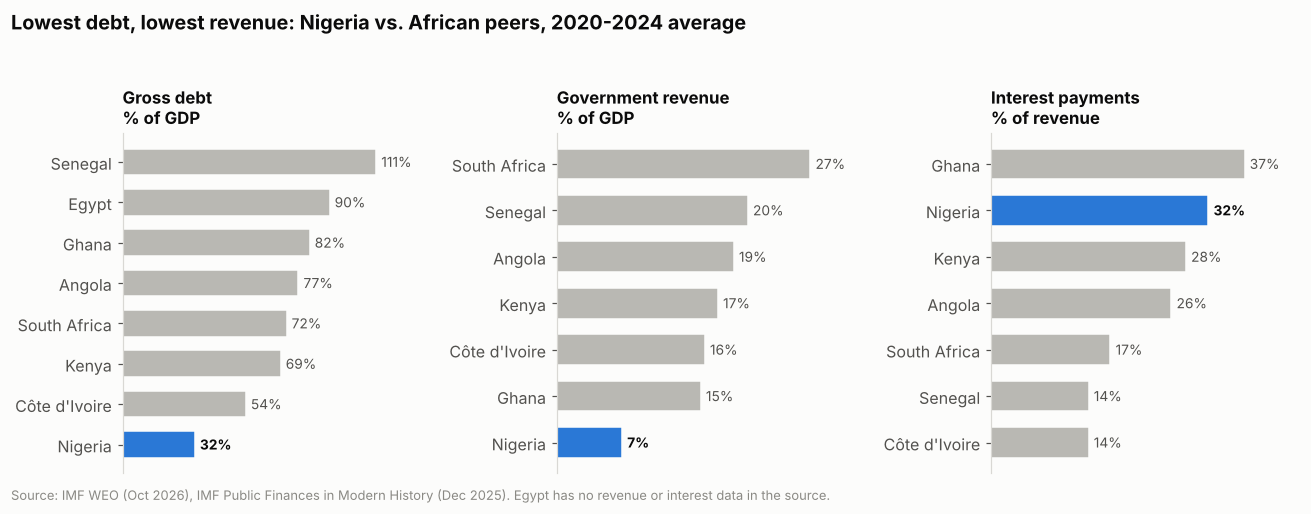

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=False)
panels = [
    ("debt_pct_gdp", "Gross debt\n% of GDP"),
    ("revenue_pct_gdp", "Government revenue\n% of GDP"),
    ("interest_pct_revenue", "Interest payments\n% of revenue"),
]
for ax, (col, title) in zip(axes, panels):
    d = recent.dropna(subset=[col]).sort_values(col)
    colors = [BLUE if c == "Nigeria" else GREY for c in d.country]
    ax.barh(d.country, d[col], color=colors, height=0.66, edgecolor="#fcfcfb", linewidth=1)
    for i, (c, v) in enumerate(zip(d.country, d[col])):
        ax.text(v + d[col].max() * 0.02, i, f"{v:.0f}%", va="center", fontsize=9,
                color=INK if c == "Nigeria" else INK_2, fontweight="bold" if c == "Nigeria" else "normal")
    ax.set_title(title, fontsize=11)
    ax.set_xlim(0, d[col].max() * 1.22)
    ax.xaxis.set_visible(False)
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
fig.suptitle("Lowest debt, lowest revenue: Nigeria vs. African peers, 2020-2024 average",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
source_note(fig, "Source: IMF WEO (Oct 2026), IMF Public Finances in Modern History (Dec 2025). Egypt has no revenue or interest data in the source.")
fig.tight_layout()
fig.savefig(CHARTS / "03_peer_comparison.png")
plt.show()

**Reading:** Over 2020-2024 Nigeria had the lowest debt ratio of the eight countries, yet it spent the second-largest share of its revenue on interest, behind only Ghana, which defaulted in 2022. Kenya, Angola, South Africa, Senegal and Côte d'Ivoire all carry far more debt but spend a smaller share of revenue servicing it. The reason is the middle panel: Nigeria collects only about a third as much revenue relative to GDP as its peers.

## 4. Sizing the revenue gap

In [10]:
gap = q("revenue_gap_vs_peers")
gap

,year,nga_revenue_pct_gdp,peer_avg_revenue_pct_gdp,gap_pp,gap_usd_bn
0,2010,8.8,20.3,11.5,60.6
1,2011,12.6,20.7,8.1,47.8
2,2012,10.4,20.8,10.3,67.9
3,2013,8.2,20.0,11.9,87.2
4,2014,7.8,19.4,11.6,94.2
5,2015,5.1,18.8,13.6,94.8
6,2016,3.6,18.0,14.4,81.9
7,2017,4.7,17.8,13.1,69.5
8,2018,6.0,18.7,12.6,74.9
9,2019,5.6,18.8,13.2,88.1


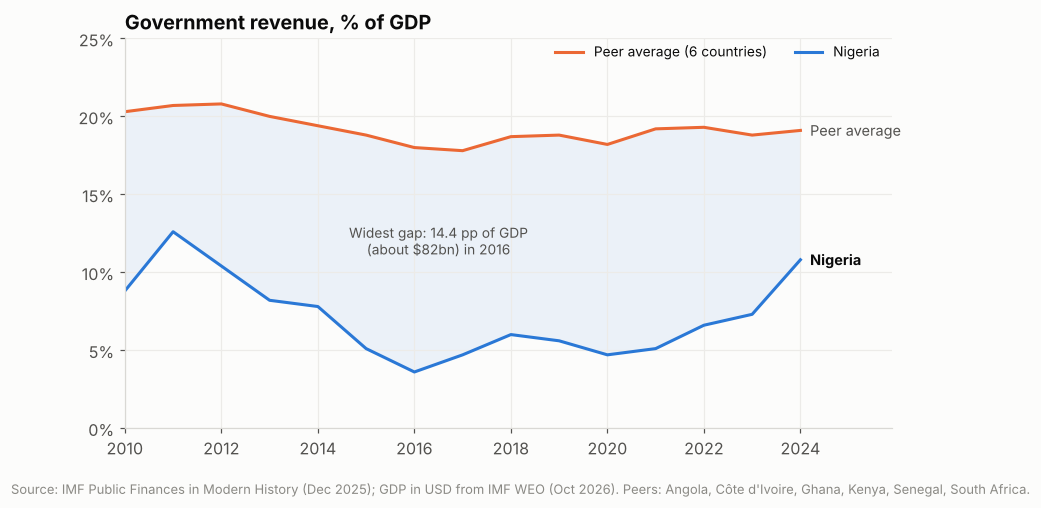

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(gap.year, gap.peer_avg_revenue_pct_gdp, color=ORANGE)
ax.plot(gap.year, gap.nga_revenue_pct_gdp, color=BLUE)
ax.fill_between(gap.year, gap.nga_revenue_pct_gdp, gap.peer_avg_revenue_pct_gdp, color=BLUE, alpha=0.08, lw=0)
ax.text(2024.2, gap.peer_avg_revenue_pct_gdp.iloc[-1], "Peer average", va="center", color=INK_2, fontsize=9.5)
ax.text(2024.2, gap.nga_revenue_pct_gdp.iloc[-1], "Nigeria", va="center", color=INK, fontsize=9.5, fontweight="bold")
peak = gap.loc[gap.gap_pp.idxmax()]
ax.text(peak.year + 0.5, 12, f"Widest gap: {peak.gap_pp:.1f} pp of GDP\n(about ${peak.gap_usd_bn:.0f}bn) in {int(peak.year)}",
        ha="center", va="center", fontsize=9, color=INK_2)
ax.legend(["Peer average (6 countries)", "Nigeria"], frameon=False, loc="upper right", bbox_to_anchor=(1, 1.02), ncol=2, fontsize=9)
ax.set_xlim(2010, 2025.9)
ax.set_xticks(range(2010, 2025, 2))
ax.set_ylim(0, 25)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Government revenue, % of GDP")
source_note(fig, "Source: IMF Public Finances in Modern History (Dec 2025); GDP in USD from IMF WEO (Oct 2026). Peers: Angola, Côte d'Ivoire, Ghana, Kenya, Senegal, South Africa.")
fig.savefig(CHARTS / "04_revenue_gap.png")
plt.show()

**Reading:** From 2010 to 2023 Nigeria's revenue ratio sat 8 to 14 percentage points below the peer average, a shortfall worth roughly $48-95bn a year at the time's exchange rates. The 2024 gap looks much smaller in dollars partly because GDP measured in dollars fell by about half after the devaluation.

## Conclusions

1. **Nigeria's debt is not high, but it is expensive relative to what the state collects.** With the lowest debt ratio in the peer group, Nigeria still spent around a third of its revenue on interest in 2020-2024.
2. **Revenue is the binding constraint.** Revenue collapsed after the 2014-15 oil-price crash and stayed near 5% of GDP until 2022; that, more than new borrowing, pushed the interest burden up.
3. **2024 shows how sensitive the picture is to revenue.** A rise in revenue to 10.8% of GDP cut the interest-to-revenue ratio from 39% to 23% in one year, even though debt kept rising.

## Limitations

- Revenue, expenditure and interest come from a different IMF dataset (Public Finances in Modern History) than debt (WEO). Coverage of government levels may differ between them, so ratios across datasets are indicative.
- Interest-to-revenue here uses ratios to GDP. Nigerian official figures for *federal* debt service to *federal retained* revenue are much higher, because the federal government keeps only part of total revenue.
- 2024 is the most recent outturn; 2025 onward are IMF projections and are shown only for debt.
- Peer averages are simple (unweighted) means.